# Exploración de datos de atún

Esta base contiene registros de captura y esfuerzo pesquero
de atunes en el Pacífico oriental entre 1958 y 2025.

In [3]:
from pathlib import Path

print("Carpeta de trabajo:", Path.cwd())

for archivo in Path(".").glob("*.csv"):
    print(archivo.name)

Carpeta de trabajo: /home/jovyan
Ballena_Jorobada_Pacifico_Norte_2025-2026.csv
PublicPSTunaSetType.csv


In [3]:
import pandas as pd

datos = pd.read_csv("PublicPSTunaSetType.csv")

datos.head(6)

,Year,Month,SetType,LatC1,LonC1,NumSets,ALB,BET,BKJ,BZX,FRZ,PBF,SKJ,TUN,YFT
0,1958,12,NOA,18.5,-114.5,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,26.3
1,1958,12,NOA,18.5,-110.5,10,0.0,0.0,0.0,0.0,0.0,0.0,54.4,0.0,0.0
2,1958,12,NOA,19.5,-110.5,6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.1
3,1959,1,NOA,15.5,-97.5,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,99.9
4,1959,1,NOA,16.5,-100.5,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,1959,1,DEL,16.5,-99.5,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.4


In [5]:
#crear el subset para C.R 
atun_region = datos[
    (datos["LatC1"] >= 7) &
    (datos["LatC1"] <= 12) &
    (datos["LonC1"] >= -89) &
    (datos["LonC1"] <= -82)
]

# Mostrar las primeras seis filas
atun_region.head(6)

,Year,Month,SetType,LatC1,LonC1,NumSets,ALB,BET,BKJ,BZX,FRZ,PBF,SKJ,TUN,YFT
141,1959,8,NOA,9.5,-85.5,4,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,27.20
198,1959,10,NOA,9.5,-85.5,76,0.0,0.0,0.0,0.0,0.0,0.0,42.87,0.0,299.12
199,1959,10,DEL,9.5,-84.5,1,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,27.20
200,1959,10,DEL,10.5,-86.5,1,0.0,0.0,0.0,0.0,0.0,0.0,9.10,0.0,18.10
201,1959,10,NOA,10.5,-86.5,1,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00
202,1959,10,NOA,11.5,-87.5,5,0.0,0.0,0.0,0.0,0.0,0.0,1.80,0.0,2.70


## Descripción de las columnas

- **Year:** año de la actividad pesquera.
- **Month:** mes, de 1 (enero) a 12 (diciembre).
- **SetType:** tipo de lance de pesca:
  - **DEL:** sobre atunes asociados con delfines.
  - **NOA:** sobre cardúmenes no asociados con delfines ni objetos flotantes.
  - **OBJ:** sobre atunes asociados con objetos flotantes.
- **LatC1:** latitud del centro de la cuadrícula; los valores positivos indican norte.
- **LonC1:** longitud del centro de la cuadrícula; los valores negativos indican oeste.
- **NumSets:** número de lances de pesca agrupados en la fila.
- **ALB:** albacora o atún blanco (*Thunnus alalunga*).
- **BET:** atún patudo (*Thunnus obesus*).
- **BKJ:** barrilete negro (*Euthynnus lineatus*).
- **BZX:** bonitos del género *Sarda*, sin precisar la especie.
- **FRZ:** melvas (*Auxis thazard* y *Auxis rochei*).
- **PBF:** atún aleta azul del Pacífico (*Thunnus orientalis*).
- **SKJ:** barrilete o listado (*Katsuwonus pelamis*).
- **TUN:** atunes no especificados en otra categoría; no es la suma de todos los atunes.
- **YFT:** atún aleta amarilla (*Thunnus albacares*). 

Cada fila agrupa datos por año, mes, cuadrícula de 1° × 1° y tipo de lance.

Fuente: https://www.iattc.org/es-es/Data/Reference-codes

In [6]:
# subset de datos para atún aleta amarilla
atun_aleta_amarilla = atun_region[
    ["Year", "Month", "SetType", "LatC1", "LonC1", "NumSets", "YFT"]
].copy()

# Mostrar las primeras seis filas
atun_aleta_amarilla.head(6)

,Year,Month,SetType,LatC1,LonC1,NumSets,YFT
141,1959,8,NOA,9.5,-85.5,4,27.20
198,1959,10,NOA,9.5,-85.5,76,299.12
199,1959,10,DEL,9.5,-84.5,1,27.20
200,1959,10,DEL,10.5,-86.5,1,18.10
201,1959,10,NOA,10.5,-86.5,1,0.00
202,1959,10,NOA,11.5,-87.5,5,2.70


- NumSets indica cuántos lances se realizaron en ese año, mes, cuadrícula y tipo de lance.
- YFT indica la captura de aleta amarilla correspondiente a esos lances.
Por ejemplo, si NumSets = 4 y YFT = 20, se registraron 20 toneladas
de aleta amarilla en cuatro lances. La captura promedio fue de
5 toneladas por lance.

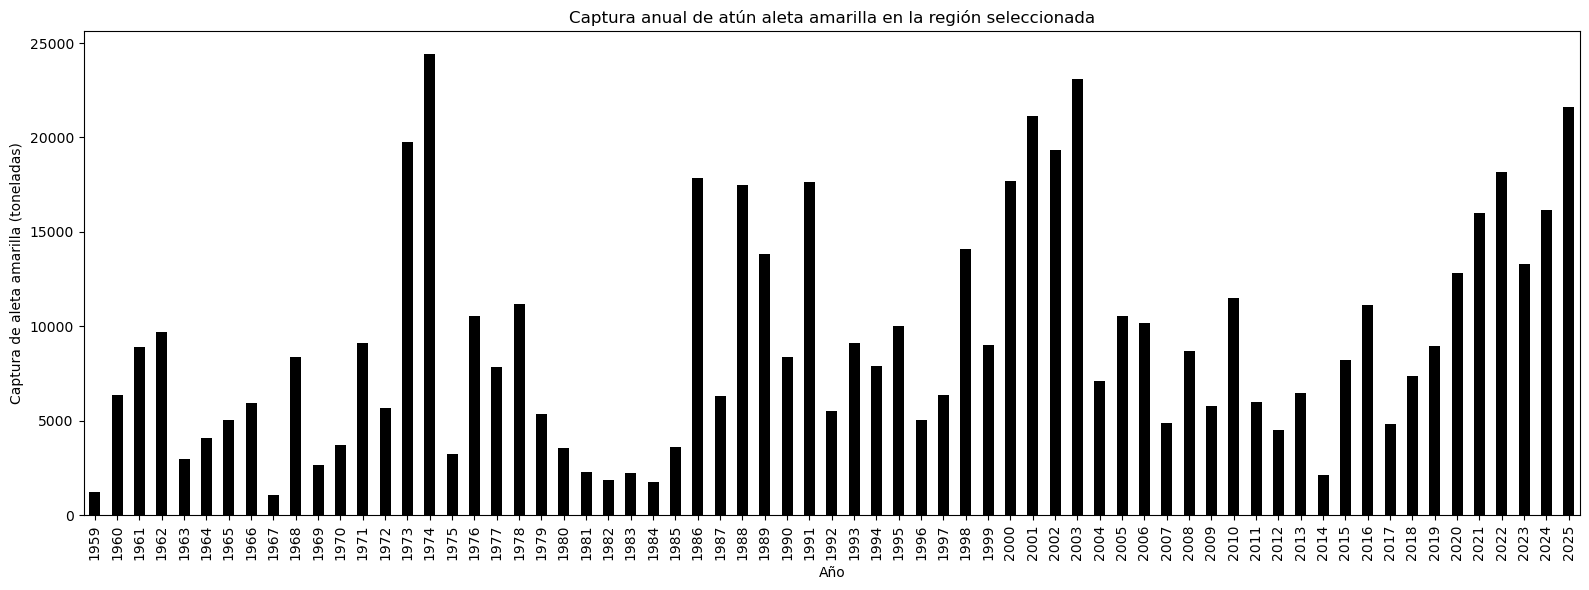

In [8]:
import matplotlib.pyplot as plt

# Sumar las toneladas capturadas por año
captura_anual = atun_aleta_amarilla.groupby("Year")["YFT"].sum()

# Crear el gráfico de barras
captura_anual.plot(kind="bar", figsize=(16, 6), color="black")

plt.xlabel("Año")
plt.ylabel("Captura de aleta amarilla (toneladas)")
plt.title("Captura anual de atún aleta amarilla en la región seleccionada")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [9]:
atun_aleta_amarilla.to_csv("atun_aleta_amarilla_region.csv", index=False)

## Propuesta de delimitación del área de estudio

**7° y 11° de latitud norte** y **87° y 93° de longitud oeste**, esto tomando como referencia la extensión del núcleo climatológico del Domo Térmico de Costa Rica descrita por Shi y Wang (2024).

Este rectángulo se utiliza como un área fija para comparar las capturas entre años, pero no representa el límite exacto del Domo en cada fecha, ya que su posición y extensión varían.

## Selección de los datos pesqueros

Entonces a partir de la base completa de la CIAT, se seleccionaron los registros cuyos centros de cuadrícula se encuentran dentro del área definida y se conservaron el año, el mes, el tipo de lance, las coordenadas, el número de lances y la captura de atún aleta amarilla (*Thunnus albacares*).


## Referencia

Shi, W., & Wang, M. (2024). Ocean variability in the Costa Rica Thermal Dome region from 2012 to 2021. *Remote Sensing, 16*(8), 1340. https://doi.org/10.3390/rs16081340

In [4]:
# Seleccionar entre 7–11° norte y 87–93° oeste
atun_domo = datos[
    (datos["LatC1"] >= 7) &
    (datos["LatC1"] <= 11) &
    (datos["LonC1"] >= -93) &
    (datos["LonC1"] <= -87)
].copy()

In [5]:
atun_domo = atun_domo[
    ["Year", "Month", "SetType", "LatC1", "LonC1", "NumSets", "YFT"]
].copy()

In [6]:
atun_domo.head(6)

,Year,Month,SetType,LatC1,LonC1,NumSets,YFT
510,1960,4,DEL,10.5,-89.5,5,86.1
581,1960,5,DEL,9.5,-90.5,3,63.5
582,1960,5,DEL,9.5,-89.5,1,18.1
585,1960,5,DEL,10.5,-90.5,1,22.7
586,1960,5,DEL,10.5,-89.5,14,399.1
587,1960,5,DEL,10.5,-88.5,4,33.6


In [7]:
atun_domo.to_csv("atun_domo_aleta_amarilla.csv", index=False)

In [20]:
# Agrupar por coordenadas y sumar los lances
lances_mapa = atun_domo.groupby(
    ["LatC1", "LonC1"]
)["NumSets"].sum().reset_index()

lances_mapa.head(6)

,LatC1,LonC1,NumSets
0,7.5,-92.5,1970
1,7.5,-91.5,1921
2,7.5,-90.5,2470
3,7.5,-89.5,2455
4,7.5,-88.5,2189
5,7.5,-87.5,2249
